**Understanding to the dataset**

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
originaldata = pd.read_csv(
    "/content/originaldataset.csv",
    skipinitialspace=True
)
#upload the data
#skip the spaces in the dataset

In [51]:
originaldata.shape
# Verify data size

(79330, 31)

In [52]:
print(originaldata.info())









<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  object 
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  object 
 12  Country                      79306 non-null  object 
 13  MarketSegment   

In [53]:
print(originaldata.value_counts())#display diff datatypes


IsCanceled  LeadTime  ArrivalDateYear  ArrivalDateMonth  ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  StaysInWeekNights  Adults  Children  Babies  Meal       Country  MarketSegment  DistributionChannel  IsRepeatedGuest  PreviousCancellations  PreviousBookingsNotCanceled  ReservedRoomType  AssignedRoomType  BookingChanges  DepositType      Agent  Company  DaysInWaitingList  CustomerType     ADR     RequiredCarParkingSpaces  TotalOfSpecialRequests  ReservationStatus  ReservationStatusDate
0           256       2016             October           43                     16                     2                     3                  2       0.0       0       BB         DEU      Online TA      TA/TO                0                0                      0                            A                 A                 0               No Deposit       9.0    333.0    0                  Transient-Party  100.75  0                         0                       Check-Out  

In [54]:

print(originaldata.head())#print first 5 rows of data


   IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth  \
0           0         6             2015             July   
1           1        88             2015             July   
2           1        65             2015             July   
3           1        92             2015             July   
4           1       100             2015             July   

   ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  \
0                     27                      1                     0   
1                     27                      1                     0   
2                     27                      1                     0   
3                     27                      1                     2   
4                     27                      2                     0   

   StaysInWeekNights  Adults  Children  ...      DepositType Agent Company  \
0                  2       1       0.0  ...  No Deposit        6.0     NaN   
1                  4       2       0.0

In [55]:

print(originaldata.select_dtypes(include="object").columns)#display names of columns values sored as text

Index(['ArrivalDateMonth', 'Meal', 'Country', 'MarketSegment',
       'DistributionChannel', 'ReservedRoomType', 'AssignedRoomType',
       'DepositType', 'CustomerType', 'ReservationStatus',
       'ReservationStatusDate'],
      dtype='object')


In [56]:
print(originaldata.isnull().sum())
print((originaldata.isnull().sum() / len(originaldata)) * 100)

IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateWeekNumber              0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           4
Babies                             0
Meal                               0
Country                           24
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
AssignedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           8131
Company                        75641
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
R

In [57]:
print(originaldata.duplicated().sum())

25902


In [58]:
originaldata[
    originaldata.duplicated(keep=False)
].head(10)
# print first duplicated values

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
8,1,62,2015,July,27,2,2,3,2,0.0,...,No Deposit,8.0,NaN,0,Transient,76.5,0,1,No-Show,2015-07-02
9,1,62,2015,July,27,2,2,3,2,0.0,...,No Deposit,8.0,NaN,0,Transient,76.5,0,1,No-Show,2015-07-02
10,0,43,2015,July,27,3,0,2,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Check-Out,2015-07-05
12,0,43,2015,July,27,3,0,2,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Check-Out,2015-07-05
17,0,43,2015,July,27,3,0,2,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Check-Out,2015-07-05
18,0,43,2015,July,27,3,0,2,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Check-Out,2015-07-05
22,0,43,2015,July,27,3,0,2,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Check-Out,2015-07-05
23,0,43,2015,July,27,3,0,2,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Check-Out,2015-07-05
73,1,87,2015,July,28,10,3,7,2,0.0,...,No Deposit,7.0,NaN,0,Transient,58.9,0,1,Canceled,2015-06-01
74,1,87,2015,July,28,10,3,7,2,0.0,...,No Deposit,7.0,NaN,0,Transient,58.9,0,1,Canceled,2015-06-01


In [59]:
originaldata.describe()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,Agent,Company,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79326.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,71199.000000,3689.000000,79330.000000,79330.000000,79330.000000,79330.000000
mean,0.417270,109.735724,2016.174285,27.177449,15.786625,0.795185,2.182957,1.850977,0.091370,0.004941,0.025615,0.079743,0.132371,0.187369,28.144721,145.271618,3.226774,105.304465,0.024367,0.546918
std,0.493111,110.948526,0.699181,13.398523,8.728451,0.885026,1.456416,0.509292,0.372177,0.084323,0.157983,0.415472,1.693411,0.608620,56.432181,119.774134,20.870890,43.602954,0.154919,0.780776
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,8.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,23.000000,2016.000000,17.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,40.000000,0.000000,79.200000,0.000000,0.000000
50%,0.000000,74.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,91.000000,0.000000,99.900000,0.000000,0.000000
75%,1.000000,163.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,219.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,629.000000,2017.000000,53.000000,31.000000,16.000000,41.000000,4.000000,3.000000,10.000000,1.000000,21.000000,72.000000,21.000000,509.000000,497.000000,391.000000,5400.000000,3.000000,5.000000


In [60]:
no_guest = originaldata[
    (originaldata["Adults"] == 0) &
    (originaldata["Children"] == 0) &
    (originaldata["Babies"] == 0)
]

print(len(no_guest))
#if no guest in reservation

167


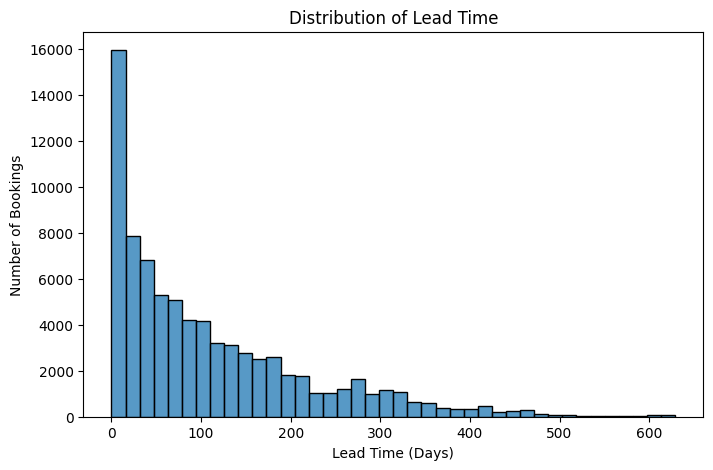

In [61]:
plt.figure(figsize=(8, 5))

sns.histplot(originaldata["LeadTime"], bins=40)

plt.title("Distribution of Lead Time")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Number of Bookings")

plt.show()

In [62]:
originaldata["TotalNights"] = (
    originaldata["StaysInWeekendNights"] +
    originaldata["StaysInWeekNights"]
)

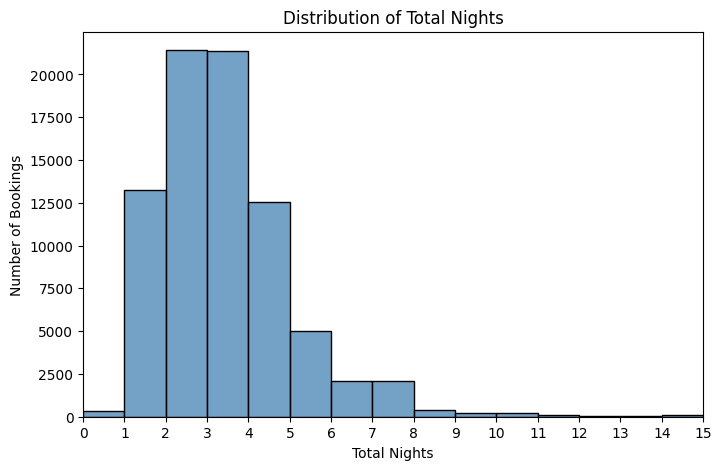

In [63]:
plt.figure(figsize=(8, 5))

sns.histplot(
    originaldata["TotalNights"],
    bins=range(0, 17),
    color="steelblue"
)

plt.xlim(0, 15)
plt.xticks(range(0, 16))

plt.title("Distribution of Total Nights")
plt.xlabel("Total Nights")
plt.ylabel("Number of Bookings")

plt.show()

In [64]:
originaldata.select_dtypes(include="object").nunique()
#unique categories

,0
ArrivalDateMonth,12
Meal,4
Country,166
MarketSegment,8
DistributionChannel,5
ReservedRoomType,8
AssignedRoomType,9
DepositType,3
CustomerType,4
ReservationStatus,3


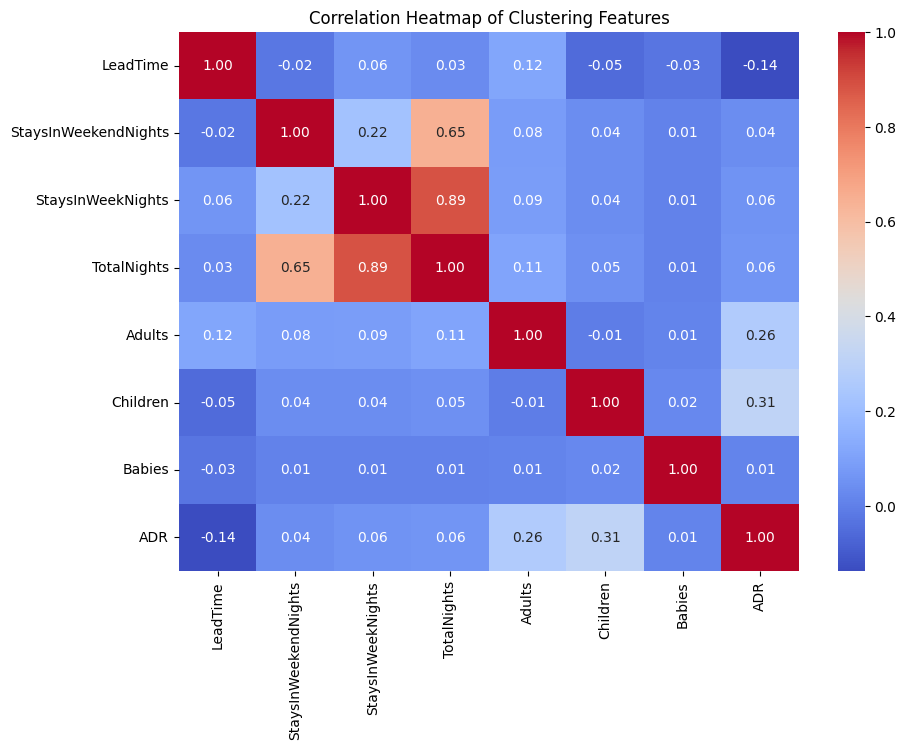

In [65]:
features = [
    "LeadTime",
    "StaysInWeekendNights",
    "StaysInWeekNights",
    "TotalNights",
    "Adults",
    "Children",
    "Babies",
    "ADR"
]

corr_matrix = originaldata[features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Clustering Features")
plt.show()